# Section 2 — Distribution Fitting and BIC Model Selection

**Training only: 2021–2023.** Fit Normal (2 parameters), Student-t (3), two-Gaussian mixture (5). All fitting occurs in **percent daily log returns**, and exported parameters are converted back to **decimal units**.

In [13]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.mixture import GaussianMixture

DATA = Path('research_data')
DATA.mkdir(exist_ok=True)
train = pd.read_csv(DATA / 'train_log_returns_2021_2023.csv', index_col=0, parse_dates=True)

TECH = ['MSFT', 'AAPL', 'NVDA', 'GOOGL', 'META', 'AMZN', 'AMD', 'INTC', 'ORCL', 'CRM']
ENERGY = ['XOM', 'CVX', 'COP', 'EOG', 'OXY', 'SLB', 'HAL', 'VLO', 'MPC', 'PSX']
TICKERS = TECH + ENERGY

## 1. Maximum-likelihood estimation

In [14]:
fits = {}
rows = []

# Fitting models
for ticker in TICKERS:
    x = 100 * train[ticker].dropna().to_numpy()
    mu, sd = stats.norm.fit(x)
    nu, loc, scale = stats.t.fit(x)
    gmm = GaussianMixture(n_components=2, covariance_type='full', n_init=10, random_state=42, reg_covar=1e-06).fit(x.reshape(-1, 1))
    fits[ticker] = {'Normal': (mu, sd), 'Student-t': (nu, loc, scale), 'GMM': gmm}

    rows.append(dict(ticker=ticker, 
                     sector='Technology' if ticker in TECH else 'Energy', 
                     n_train=len(x), 
                     normal_mu=mu / 100, normal_sigma=sd / 100, 
                     t_df=nu, t_loc=loc / 100, t_scale=scale / 100, 
                     gmm_weight_1=gmm.weights_[0], gmm_weight_2=gmm.weights_[1], 
                     gmm_mean_1=gmm.means_[0, 0] / 100, gmm_mean_2=gmm.means_[1, 0] / 100, 
                     gmm_std_1=np.sqrt(gmm.covariances_[0, 0, 0]) / 100, gmm_std_2=np.sqrt(gmm.covariances_[1, 0, 0]) / 100
                     ))

# Save para
params = pd.DataFrame(rows)
display(params.head())
params.to_csv(DATA / 'fitted_models_2021_2023.csv', index=False)

,ticker,sector,n_train,normal_mu,normal_sigma,t_df,t_loc,t_scale,gmm_weight_1,gmm_weight_2,gmm_mean_1,gmm_mean_2,gmm_std_1,gmm_std_2
0,MSFT,Technology,752,0.000762,0.017504,6.123109,0.000868,0.014452,0.503478,0.496522,0.007279,-5.845952e-03,0.015894,0.016559
1,AAPL,Technology,752,0.000552,0.017482,5.934048,0.000777,0.014350,0.574146,0.425854,0.006259,-7.142982e-03,0.015300,0.017291
2,NVDA,Technology,752,0.001770,0.033001,6.309357,0.001444,0.027205,0.485132,0.514868,0.003649,-3.922023e-07,0.041469,0.022099
3,GOOGL,Technology,752,0.000640,0.019984,4.359760,0.000710,0.015045,0.657803,0.342197,0.000897,1.474563e-04,0.013227,0.028815
4,META,Technology,752,0.000365,0.030249,3.427934,0.001057,0.018158,0.064809,0.935191,-0.007862,9.354195e-04,0.087761,0.020968


## 2. Training BIC
Smaller BIC is better.

In [ ]:
rows = []

for ticker in TICKERS:
    x = 100 * train[ticker].dropna().to_numpy()
    f = fits[ticker]
    ll = {'Normal': stats.norm.logpdf(x, *f['Normal']).sum(), 'Student-t': stats.t.logpdf(x, *f['Student-t']).sum(), 'GMM': f['GMM'].score_samples(x.reshape(-1, 1)).sum()}
    for model, k in [('Normal', 2), ('Student-t', 3), ('GMM', 5)]:
        rows.append(dict(ticker=ticker, 
                         sector='Technology' if ticker in TECH else 'Energy', 
                         model=model, 
                         train_loglik=ll[model], 
                         BIC=k * np.log(len(x)) - 2 * ll[model]
                         ))

# Save results
bic = pd.DataFrame(rows)
bic.to_csv(DATA / 'stock_training_bic.csv', index=False)
wide = bic.pivot(index='ticker', columns='model', values='BIC').reindex(TICKERS)

print('Best-BIC model counts:')
display(wide.idxmin(axis=1).value_counts())
display(wide.round(1))

Best-BIC model counts:


Student-t    20
Name: count, dtype: int64

model,GMM,Normal,Student-t
ticker,,,
MSFT,3012.7,2989.4,2962.2
AAPL,3008.5,2987.5,2960.0
NVDA,3929.8,3943.0,3905.9
GOOGL,3146.2,3188.6,3129.8
META,3547.5,3812.1,3515.2
AMZN,3364.4,3435.9,3340.7
AMD,3919.3,3896.7,3871.6
INTC,3354.1,3393.4,3333.9
ORCL,2920.1,3105.4,2896.5


## 3. Representative distribution plots

**步骤 1/3：**单独绘图，避免把模型计算和图形设置挤在同一代码单元。

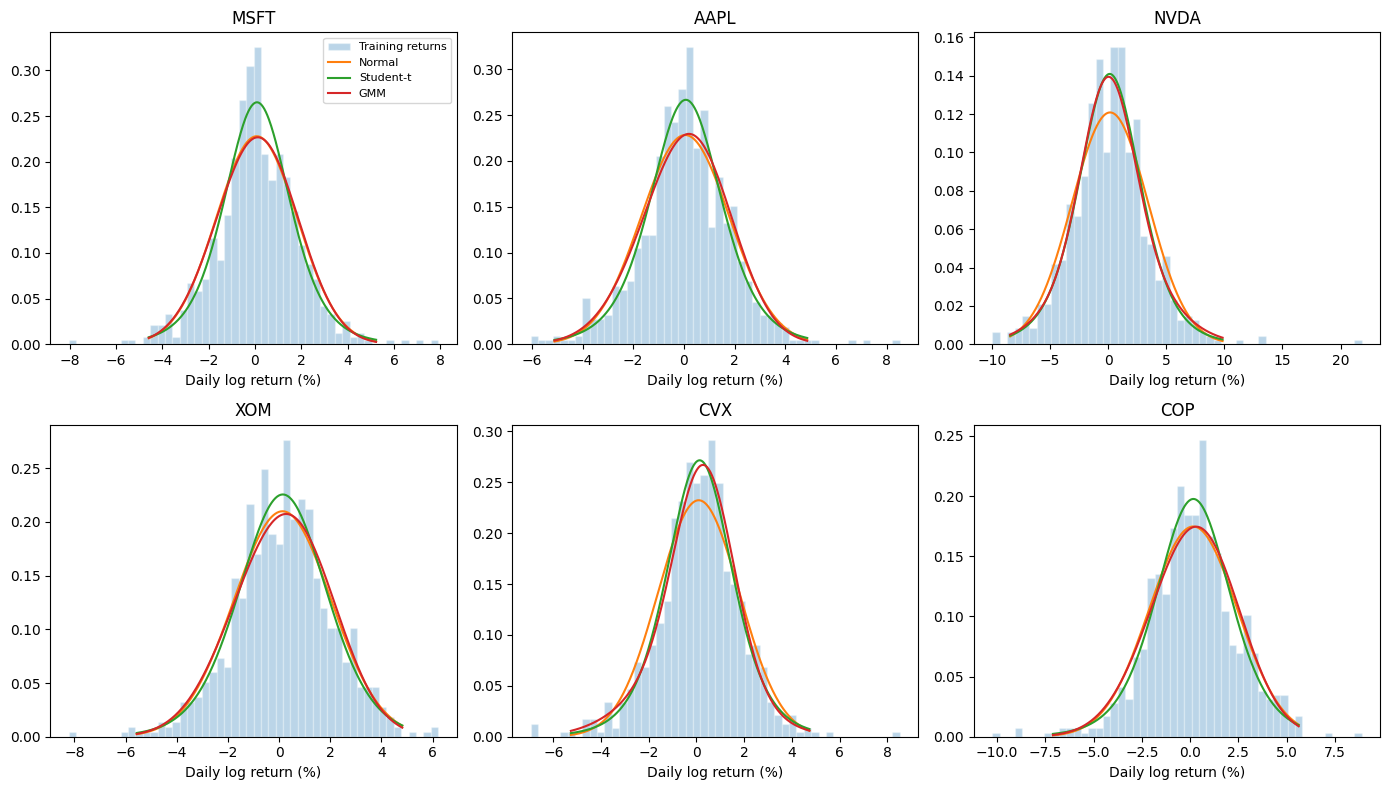

In [18]:
chosen = ['MSFT', 'AAPL', 'NVDA', 'XOM', 'CVX', 'COP']

fig, axes = plt.subplots(2, 3, figsize=(14, 8))

for ax, ticker in zip(axes.flat, chosen):
    x = 100 * train[ticker].dropna().to_numpy()
    f = fits[ticker]
    grid = np.linspace(np.quantile(x, 0.005), np.quantile(x, 0.995), 300)

    # Histographs
    ax.hist(x, bins=50, density=True, alpha=0.3, label='Training returns', edgecolor='white')
    
    # Fitting curves
    ax.plot(grid, stats.norm.pdf(grid, *f['Normal']), label='Normal')
    ax.plot(grid, stats.t.pdf(grid, *f['Student-t']), label='Student-t')
    ax.plot(grid, np.exp(f['GMM'].score_samples(grid.reshape(-1, 1))), label='GMM')
    
    ax.set_title(ticker)
    ax.set_xlabel('Daily log return (%)')
axes[0, 0].legend(fontsize=8)

plt.tight_layout()
plt.show()

## 4. Compare models using ΔBIC (training data only)

**Goal:** For each stock, measure how far each model is from the best-fitting model according to BIC. 

For stock $i$ and model $m$,

$$\Delta\mathrm{BIC}_{i,m}=\mathrm{BIC}_{i,m}-\min_j\mathrm{BIC}_{i,j}.$$

- **ΔBIC = 0**: the model with the lowest BIC for this stock.
- **ΔBIC > 0**: worse BIC relative to the best model for the same stock.
- Each row is calculated independently; **do not** subtract one stock's BIC from another's.

In [ ]:
bic_table = wide.reindex(index=TICKERS, columns=['Normal', 'Student-t', 'GMM'])

best_bic_per_stock = bic_table.min(axis=1)  # compare the same row 3 models

# Calculate delta_bic
delta_bic = bic_table.sub(best_bic_per_stock, axis=0)

print('ΔBIC relative to the best model for each stock:')
display(delta_bic.round(2))

ΔBIC relative to the best model for each stock:


model,Normal,Student-t,GMM
ticker,,,
MSFT,27.14,0.0,50.48
AAPL,27.52,0.0,48.50
NVDA,37.09,0.0,23.92
GOOGL,58.78,0.0,16.39
META,296.83,0.0,32.23
AMZN,95.16,0.0,23.62
AMD,25.11,0.0,47.63
INTC,59.52,0.0,20.17
ORCL,208.88,0.0,23.64


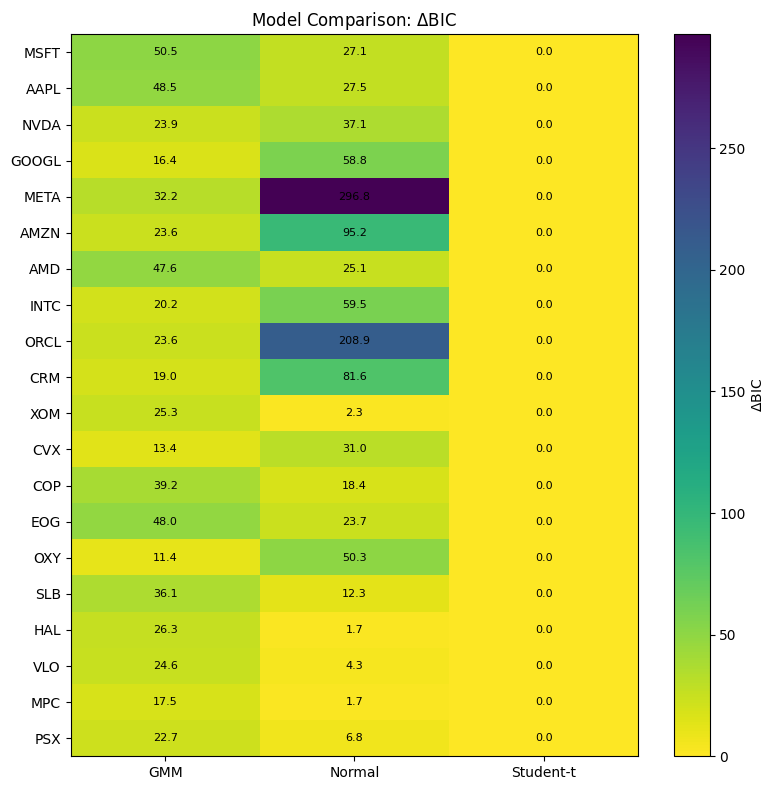

In [25]:
#  Draw the ΔBIC heatmap

plot_delta_bic = delta_bic[['GMM', 'Normal', 'Student-t']]

fig, ax = plt.subplots(figsize=(8, 8))

im = ax.imshow(
    plot_delta_bic.to_numpy(),
    cmap='viridis_r',
    aspect='auto'
)

# Label the horizontal axis with model names.
ax.set_xticks(range(len(plot_delta_bic.columns)))
ax.set_xticklabels(plot_delta_bic.columns)

# Label the vertical axis with stock tickers.
ax.set_yticks(range(len(plot_delta_bic.index)))
ax.set_yticklabels(plot_delta_bic.index)

# Restore the numeric ΔBIC annotation in each cell.
for row_index in range(len(plot_delta_bic.index)):
    for column_index in range(len(plot_delta_bic.columns)):
        value = plot_delta_bic.iloc[row_index, column_index]
        ax.text(
            column_index,
            row_index,
            f'{value:.1f}',
            ha='center',
            va='center',
            fontsize=8
        )

ax.set_title(r'Model Comparison: $\Delta$BIC')
fig.colorbar(im, ax=ax, label=r'$\Delta$BIC')

plt.tight_layout()
plt.savefig(DATA / 'delta_bic_20stocks.png', dpi=300)
plt.show()

In [26]:
best_model = bic_table.idxmin(axis=1)
selection = pd.DataFrame({'ticker': TICKERS, 'sector': ['Technology' if ticker in TECH else 'Energy' for ticker in TICKERS], 'best_model': best_model.to_numpy()})

print('Number of stocks selecting each model:')
display(selection['best_model'].value_counts())
print('Counts by sector:')
display(pd.crosstab(selection['sector'], selection['best_model']))

Number of stocks selecting each model:


best_model
Student-t    20
Name: count, dtype: int64

Counts by sector:


best_model,Student-t
sector,
Energy,10
Technology,10


## 5. Student-t degrees of freedom

In [37]:
# Extract fitted Student-t degrees of freedom

student_df_by_stock = params[['ticker', 'sector', 't_df']].copy()
student_df_display = student_df_by_stock.rename(columns={'t_df': 'Student-t df (nu)'})

display(student_df_display)

student_df_summary = params.groupby('sector')['t_df'].agg(['mean', 'median', 'min', 'max'])

print('Student-t degrees of freedom by sector (2021–2023):')
display(student_df_summary.round(3))

,ticker,sector,Student-t df (nu)
0,MSFT,Technology,6.123109
1,AAPL,Technology,5.934048
2,NVDA,Technology,6.309357
3,GOOGL,Technology,4.359760
4,META,Technology,3.427934
5,AMZN,Technology,4.188028
6,AMD,Technology,6.251212
7,INTC,Technology,4.757117
8,ORCL,Technology,3.472079
9,CRM,Technology,4.158264


Student-t degrees of freedom by sector (2021–2023):


,mean,median,min,max
sector,,,,
Energy,8.370,8.152,4.514,11.683
Technology,4.898,4.558,3.428,6.309


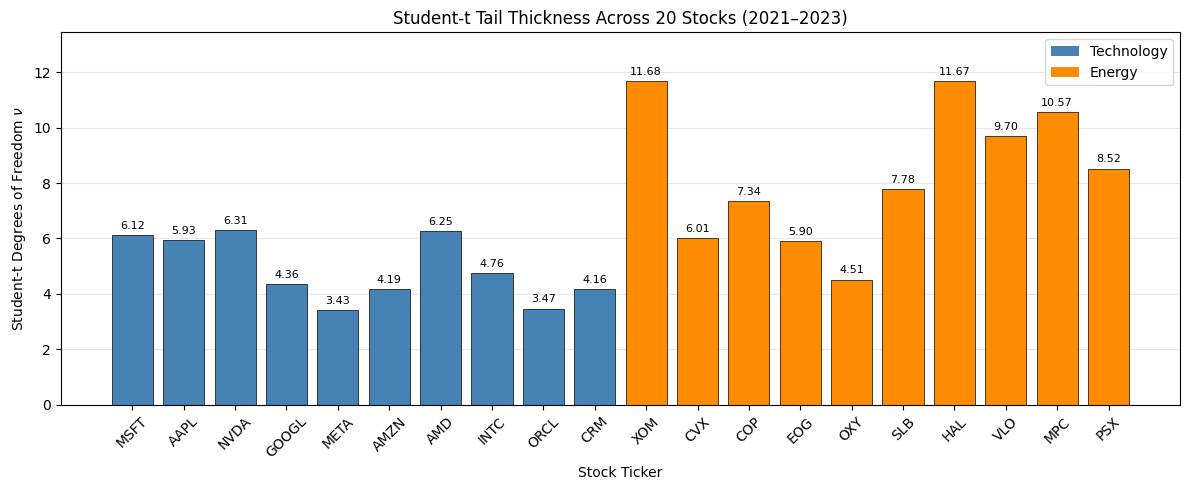

In [38]:
# Plot Student-t Degrees of Freedom

technology_stocks = student_df_by_stock[
    student_df_by_stock['sector'] == 'Technology'
]
energy_stocks = student_df_by_stock[
    student_df_by_stock['sector'] == 'Energy'
]
student_df_plot = pd.concat(
    [technology_stocks, energy_stocks],
    ignore_index=True
)

tickers = student_df_plot['ticker']
nu_values = student_df_plot['t_df']

colors = [
    'steelblue' if sector == 'Technology' else 'darkorange'
    for sector in student_df_plot['sector']
]

fig, ax = plt.subplots(figsize=(12, 5))

bars = ax.bar(
    tickers,
    nu_values,
    color=colors,
    edgecolor='black',
    linewidth=0.5
)

for bar, nu in zip(bars, nu_values):

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.15,
        f'{nu:.2f}',
        ha='center',
        va='bottom',
        fontsize=8
    )

ax.set_xlabel('Stock Ticker')
ax.set_ylabel(r'Student-t Degrees of Freedom $\nu$')
ax.set_title('Student-t Tail Thickness Across 20 Stocks (2021–2023)')

ax.grid(axis='y', alpha=0.3)
ax.set_axisbelow(True)
ax.tick_params(axis='x', rotation=45)
ax.set_ylim(0, nu_values.max() * 1.15)

from matplotlib.patches import Patch

legend_elements = [
    Patch(facecolor='steelblue', label='Technology'),
    Patch(facecolor='darkorange', label='Energy')
]

ax.legend(handles=legend_elements)

plt.tight_layout()

plt.savefig(
    'student_t_tail_thickness_20stocks.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

## 6. Training-only empirical extreme-return frequency

In [39]:
tail = []

for ticker in TICKERS:
    x = train[ticker].dropna().to_numpy()
    mu = x.mean()
    sd = x.std(ddof=0)
    tail.append({'ticker': ticker, 'sector': 'Technology' if ticker in TECH else 'Energy', 'abs_gt_2sigma_pct': 100 * np.mean(np.abs(x - mu) > 2 * sd)})

# Save tail
tail = pd.DataFrame(tail)
display(tail.groupby('sector')['abs_gt_2sigma_pct'].agg(['mean', 'median']))
tail.to_csv(DATA / 'stock_training_tail_frequency.csv', index=False)

,mean,median
sector,,
Energy,5.106383,5.053191
Technology,4.787234,4.920213
